# 01 · EDA & Business Insights — Review ví MoMo trên Google Play

**Câu hỏi nghiệp vụ**
1. Mức độ hài lòng của người dùng thay đổi thế nào theo thời gian và theo phiên bản app?
2. Bản cập nhật nào làm trải nghiệm xấu đi (cần cảnh báo sớm)?
3. MoMo phản hồi người dùng nhanh và đầy đủ đến đâu?
4. Phân phối rating có gì bất thường (phân cực, spam) cần lưu ý khi dùng làm nhãn cho ML?

Dữ liệu: toàn bộ review công khai crawl bằng `google-play-scraper` (`src/momo_reviews/crawl.py`), đã làm sạch bằng `src/momo_reviews/preprocess.py`. Không lưu tên/ảnh người dùng.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display, Markdown

from momo_reviews.config import CLEAN_FILE
from momo_reviews.viz import set_style, save, SENTIMENT_COLORS, BLUE, INK_2
set_style()
pd.set_option("display.max_colwidth", 160)

df = pd.read_parquet(CLEAN_FILE)
print(f"{len(df):,} review | {df['at'].min():%d/%m/%Y} → {df['at'].max():%d/%m/%Y}")

217,336 review | 28/05/2014 → 22/10/2026


## 1. Tổng quan dữ liệu & KPI

In [2]:
kpi = pd.Series({
    "Số review": f"{len(df):,}",
    "Rating trung bình": f"{df['score'].mean():.2f} ★",
    "% tiêu cực (1–2★)": f"{(df['sentiment']=='negative').mean():.1%}",
    "% tích cực (4–5★)": f"{(df['sentiment']=='positive').mean():.1%}",
    "% có nội dung text": f"{(df['n_words']>0).mean():.1%}",
    "% được MoMo trả lời": f"{df['has_reply'].mean():.1%}",
    "% review spam/quảng cáo": f"{df['is_spam'].mean():.2%}",
    "% thiếu appVersion": f"{df['version'].isna().mean():.1%}",
}, name="Giá trị")
kpi.to_frame()

,Giá trị
Số review,"217,336"
Rating trung bình,3.37 ★
% tiêu cực (1–2★),38.3%
% tích cực (4–5★),57.5%
% có nội dung text,99.9%
% được MoMo trả lời,16.3%
% review spam/quảng cáo,0.10%
% thiếu appVersion,23.2%


In [3]:
missing = df[["content", "version", "replyContent", "thumbsUpCount"]].isna().mean().rename("tỷ lệ thiếu")
missing.to_frame().style.format("{:.1%}")

,tỷ lệ thiếu
content,0.0%
version,23.2%
replyContent,83.7%
thumbsUpCount,0.0%


## 2. Phân phối rating — phân cực "J-shape"

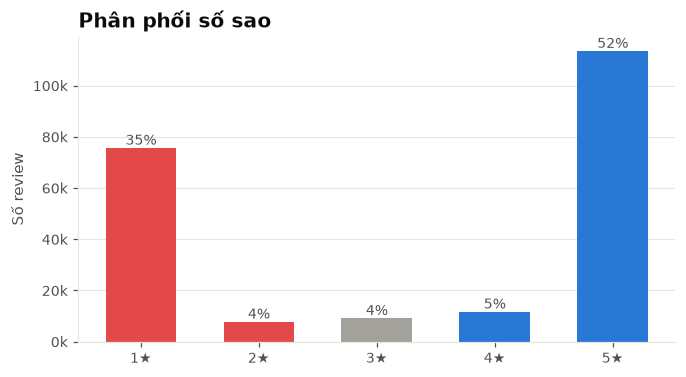

In [4]:
dist = df["score"].value_counts().sort_index()
colors = [SENTIMENT_COLORS[s] for s in ["negative", "negative", "neutral", "positive", "positive"]]
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(dist.index.astype(str) + "★", dist.values, color=colors, width=0.6)
for b, v in zip(bars, dist.values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v/dist.sum():.0%}", ha="center", va="bottom", fontsize=9, color=INK_2)
ax.set_title("Phân phối số sao"); ax.set_ylabel("Số review")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
ax.grid(axis="x", visible=False)
save(fig, "01_rating_distribution"); plt.show()

**Nhận xét.** Rating phân cực mạnh: rất nhiều 5★ và 1★, rất ít 2–3★. Đây là đặc trưng của review app (người dùng chỉ viết khi rất vui hoặc rất bực).
Hệ quả cho ML: lớp *neutral* rất hiếm → phải dùng **macro-F1** thay vì accuracy và cân bằng trọng số lớp.

## 3. Xu hướng theo thời gian

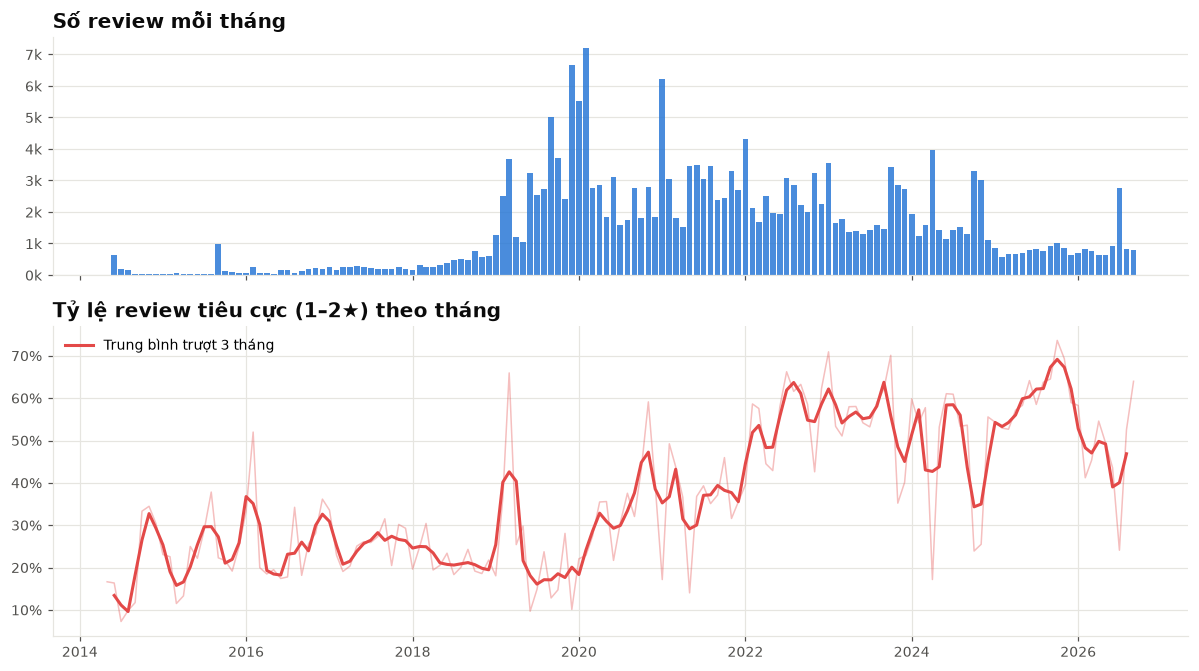

In [5]:
monthly = df.groupby("month").agg(n=("reviewId", "size"), avg=("score", "mean"),
                                  neg=("sentiment", lambda s: (s == "negative").mean()))
monthly = monthly[monthly.index < monthly.index.max()]  # bỏ tháng hiện tại chưa đủ dữ liệu

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
axes[0].bar(monthly.index, monthly["n"], width=25, color=BLUE, alpha=0.85)
axes[0].set_title("Số review mỗi tháng"); axes[0].grid(axis="x", visible=False)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))

axes[1].plot(monthly.index, monthly["neg"], color=SENTIMENT_COLORS["negative"], alpha=0.35, linewidth=1)
axes[1].plot(monthly.index, monthly["neg"].rolling(3, center=True).mean(),
             color=SENTIMENT_COLORS["negative"], label="Trung bình trượt 3 tháng")
axes[1].set_title("Tỷ lệ review tiêu cực (1–2★) theo tháng")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].legend(loc="upper left")
fig.tight_layout(); save(fig, "01_monthly_trend"); plt.show()

In [6]:
yearly = df.groupby("year").agg(review=("reviewId", "size"), rating_tb=("score", "mean"),
                                ty_le_tieu_cuc=("sentiment", lambda s: (s == "negative").mean()),
                                ty_le_tra_loi=("has_reply", "mean"))
yearly["tang_truong_yoy"] = yearly["review"].pct_change()
yearly.style.format({"review": "{:,}", "rating_tb": "{:.2f}", "ty_le_tieu_cuc": "{:.1%}",
                     "ty_le_tra_loi": "{:.1%}", "tang_truong_yoy": "{:+.0%}"}, na_rep="—") \
      .background_gradient(subset=["ty_le_tieu_cuc"], cmap="Reds")

,review,rating_tb,ty_le_tieu_cuc,ty_le_tra_loi,tang_truong_yoy
year,,,,,
2014,"1,089",4.14,14.9%,72.8%,—
2015,"1,623",3.84,22.3%,76.6%,+49%
2016,"1,559",3.57,29.3%,90.4%,-4%
2017,"2,759",3.74,26.0%,1.1%,+77%
2018,"5,120",3.98,21.3%,0.2%,+86%
2019,"36,043",4.00,22.4%,3.5%,+604%
2020,"35,843",3.64,31.1%,20.6%,-1%
2021,"36,880",3.58,32.9%,3.4%,+3%
2022,"30,203",2.77,53.5%,4.3%,-18%


In [7]:
top_months = monthly.assign(z=(monthly["neg"] - monthly["neg"].rolling(12, min_periods=6).mean())
                              / monthly["neg"].rolling(12, min_periods=6).std())
display(Markdown("**Các tháng tỷ lệ tiêu cực tăng đột biến (z-score so với 12 tháng trước > 2):**"))
top_months[top_months["z"] > 2][["n", "avg", "neg", "z"]].sort_values("z", ascending=False).head(10) \
    .style.format({"n": "{:,}", "avg": "{:.2f}", "neg": "{:.1%}", "z": "{:.1f}"})

**Các tháng tỷ lệ tiêu cực tăng đột biến (z-score so với 12 tháng trước > 2):**

,n,avg,neg,z
month,,,,
2019-03-01 00:00:00,"3,687",2.32,66.0%,3.0
2019-02-01 00:00:00,"2,514",3.46,36.4%,2.5
2016-02-01 00:00:00,250,2.78,52.0%,2.4
2020-11-01 00:00:00,"2,789",2.50,59.1%,2.2
2022-02-01 00:00:00,"2,130",2.57,58.6%,2.0


**Ứng dụng.** Bảng trên là một **cơ chế cảnh báo bất thường** đơn giản: nếu chạy hằng tuần, team sản phẩm sẽ biết ngay khi một sự cố/bản cập nhật làm tỷ lệ phàn nàn vọt lên — trước khi rating tổng trên Store bị ảnh hưởng.

## 4. Rating theo phiên bản app

In [8]:
by_major = (df.dropna(subset=["major_version"])
              .groupby("major_version")
              .agg(n=("reviewId", "size"), rating=("score", "mean"),
                   neg=("sentiment", lambda s: (s == "negative").mean()),
                   tu=("at", "min"), den=("at", "max")))
by_major = by_major[by_major["n"] >= 200].sort_index(key=lambda i: i.astype(int))
by_major.style.format({"n": "{:,}", "rating": "{:.2f}", "neg": "{:.1%}",
                       "tu": "{:%m/%Y}", "den": "{:%m/%Y}"})

,n,rating,neg,tu,den
major_version,,,,,
1,"3,010",3.72,25.1%,05/2014,09/2021
2,"59,387",3.89,24.7%,01/2017,10/2026
3,"45,415",3.30,39.7%,10/2020,10/2026
4,"51,798",2.91,50.4%,07/2022,10/2026
5,"7,288",3.27,41.9%,10/2025,10/2026


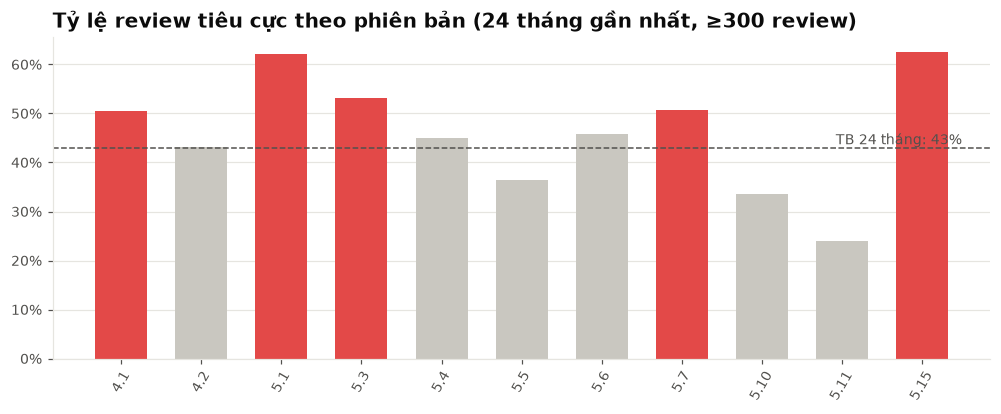

Phiên bản tô đỏ có tỷ lệ tiêu cực cao hơn trung bình >15% — ứng viên để soát lại release notes / crash log.

In [9]:
recent = df[df["at"] >= df["at"].max() - pd.DateOffset(months=24)].dropna(subset=["version"])
recent = recent.assign(minor=recent["version"].str.extract(r"^(\d+\.\d+)")[0])
by_minor = recent.groupby("minor").agg(n=("reviewId", "size"), neg=("sentiment", lambda s: (s == "negative").mean()),
                                       first=("at", "min"))
by_minor = by_minor[by_minor["n"] >= 300]
by_minor = by_minor.loc[sorted(by_minor.index, key=lambda v: tuple(int(x) for x in v.split(".")))]
base = (recent["sentiment"] == "negative").mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
col = [SENTIMENT_COLORS["negative"] if v > base * 1.15 else "#c9c7c0" for v in by_minor["neg"]]
ax.bar(by_minor.index, by_minor["neg"], color=col, width=0.65)
ax.axhline(base, color=INK_2, linestyle="--", linewidth=1)
ax.text(len(by_minor) - 0.5, base, f" TB 24 tháng: {base:.0%}", va="bottom", ha="right", fontsize=9, color=INK_2)
ax.set_title("Tỷ lệ review tiêu cực theo phiên bản (24 tháng gần nhất, ≥300 review)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.tick_params(axis="x", rotation=60)
ax.grid(axis="x", visible=False)
save(fig, "01_negative_by_version"); plt.show()
display(Markdown("Phiên bản tô đỏ có tỷ lệ tiêu cực cao hơn trung bình >15% — ứng viên để soát lại release notes / crash log."))

## 5. MoMo phản hồi người dùng như thế nào?

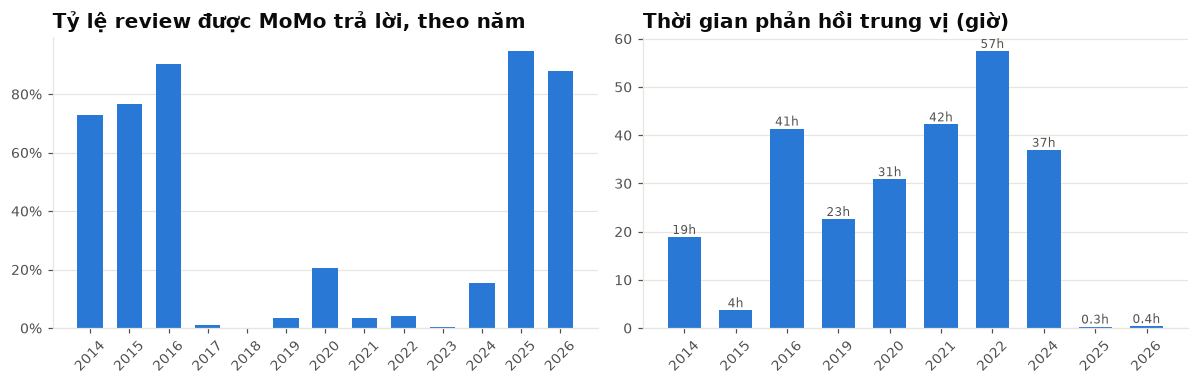

Tỷ lệ trả lời theo nhóm cảm xúc: negative: 24%, neutral: 21%, positive: 11%
trung vị thời gian phản hồi: 18.5 giờ


In [10]:
reply = df.groupby("year").agg(rate=("has_reply", "mean"), n_reply=("has_reply", "sum"))
replied = df[df["has_reply"] & (df["reply_hours"] >= 0)]
reply_time = replied.groupby("year")["reply_hours"].median()
reply_time = reply_time[reply.loc[reply_time.index, "n_reply"] >= 100]   # bỏ năm quá ít reply

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(reply.index.astype(str), reply["rate"], color=BLUE, width=0.65)
axes[0].set_title("Tỷ lệ review được MoMo trả lời, theo năm"); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].tick_params(axis="x", rotation=45); axes[0].grid(axis="x", visible=False)
axes[1].bar(reply_time.index.astype(str), reply_time.values, color=BLUE, width=0.65)
for x, v in zip(reply_time.index.astype(str), reply_time.values):
    axes[1].text(x, v, f"{v:.1f}h" if v < 1 else f"{v:.0f}h", ha="center", va="bottom", fontsize=8, color=INK_2)
axes[1].set_title("Thời gian phản hồi trung vị (giờ)"); axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "01_reply_behaviour"); plt.show()
print("Tỷ lệ trả lời theo nhóm cảm xúc: " + ", ".join(f"{k}: {v:.0%}" for k, v in df.groupby("sentiment")["has_reply"].mean().items()))
print(f"trung vị thời gian phản hồi: {replied['reply_hours'].median():.1f} giờ")

**Nhận xét.** Chính sách phản hồi thay đổi rõ rệt: giai đoạn 2017–2023 gần như không trả lời review, từ 2025 tỷ lệ trả lời vọt lên ~90%+ với thời gian phản hồi < 1 giờ — nhiều khả năng là phản hồi tự động/bán tự động. Bước tiếp theo nên đo xem phản hồi có *giải quyết được vấn đề* hay không (vd: người dùng sửa rating sau khi được trả lời).

## 6. Review nào được cộng đồng đồng tình nhất?

In [11]:
helpful = df.groupby("sentiment")["thumbsUpCount"].agg(["mean", "median", lambda s: (s > 0).mean()])
helpful.columns = ["thumbs_up_tb", "trung_vi", "% có ≥1 like"]
display(helpful.style.format({"thumbs_up_tb": "{:.2f}", "trung_vi": "{:.0f}", "% có ≥1 like": "{:.1%}"}))
display(Markdown("**Top 8 review tiêu cực được nhiều người 'hữu ích' nhất trong 12 tháng gần đây** — tiếng nói đại diện cho nhiều người dùng:"))
last12 = df[df["at"] >= df["at"].max() - pd.DateOffset(months=12)]
last12[last12.sentiment == "negative"].nlargest(8, "thumbsUpCount")[["at", "score", "thumbsUpCount", "version", "content"]]

,thumbs_up_tb,trung_vi,% có ≥1 like
sentiment,,,
negative,2.63,0,28.8%
neutral,1.72,0,21.6%
positive,0.52,0,14.1%


**Top 8 review tiêu cực được nhiều người 'hữu ích' nhất trong 12 tháng gần đây** — tiếng nói đại diện cho nhiều người dùng:

,at,score,thumbsUpCount,version,content
214505,2026-07-23 14:12:20,1,217,5.11.0,"- mỗi tháng đều hiện nhắc thông báo có chuyển tiền định kỳ cho ngân hàng nào đó không biết, không có chỗ tắt - mấy hôm nay cực kì lag, mất 10-15s mỗi lần th..."
209123,2026-02-15 15:17:41,1,176,5.5.0,chuyển khoản bị treo trừ tiền 2 ngày vẫn không giải quyết. làm riết sợ sử dụng app này luôn.
207571,2025-12-12 08:14:50,1,130,5.2.1,"app tệ, link bank thì cứ không thanh toán qua bank mà bắt nạp tiền mới cho tt. vô dụng"
207918,2025-12-31 20:33:06,1,126,5.3.0,"như quần hỗ trợ không rành gì, nạp 3g thành công mà không vô mạng được bấm cũng như không hổ trợ vậy. Lần này nạp 100k cho tài khoản game, trừ tiền trong ng..."
215482,2026-08-12 20:22:12,1,125,5.13.1,"momo lỗi trên redmi turbo 4 bro. k dùng dc. quét mặt, điện tổng đài cũng k hỗ trợ giải quyết được. đành xóa app"
216967,2026-10-09 01:25:30,1,112,5.16.0,"Ai sử dụng Momo liên kết ngân hàng nên hủy đi nhé. Momo chỉ là app trung gian, thông tin của khách hàng bị lộ và hack tiền không lí do. liên hệ xử lí thì tự..."
210566,2026-04-16 23:15:30,1,109,5.7.1,phần mềm momo bị lỗi không vào được xin hỗ trợ
211620,2026-06-08 21:35:38,1,108,5.9.0,"khá tốt về thống kê chi têu giữa các tháng, cái app phiền chết đi được, giờ nghĩ trưa mà thông báo liền tù tì, toàn chương trình gì đâu không, cskh vào để n..."


## 7. Độ dài review & thời điểm viết

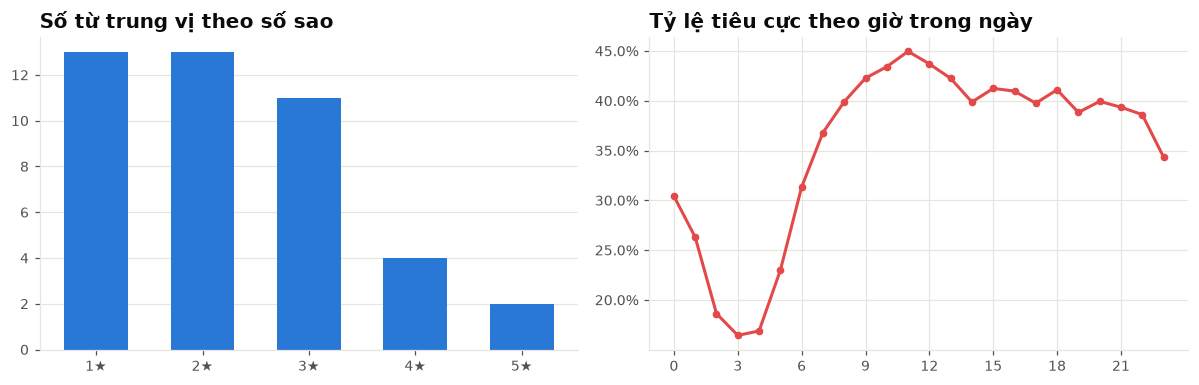

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
med_len = df[df.n_words > 0].groupby("score")["n_words"].median()
axes[0].bar(med_len.index.astype(str) + "★", med_len.values, color=BLUE, width=0.6)
axes[0].set_title("Số từ trung vị theo số sao"); axes[0].grid(axis="x", visible=False)

neg_hour = df.groupby("hour")["sentiment"].apply(lambda s: (s == "negative").mean())
axes[1].plot(neg_hour.index, neg_hour.values, marker="o", markersize=4, color=SENTIMENT_COLORS["negative"])
axes[1].set_title("Tỷ lệ tiêu cực theo giờ trong ngày"); axes[1].set_xticks(range(0, 24, 3))
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
fig.tight_layout(); save(fig, "01_length_and_hour"); plt.show()

**Nhận xét.** Review tiêu cực dài hơn hẳn review tích cực ("Tốt", "Ok") → chứa nhiều thông tin hơn về *vấn đề cụ thể*. Đây là lý do notebook 03 tập trung khai thác text của review tiêu cực.
Review 5★ ngắn, nhiều review chỉ 1–2 từ → giới hạn tự nhiên của việc học cảm xúc từ text cho lớp positive là thấp, nhưng lại dễ phân loại.

## 8. Tóm tắt cho stakeholder
Các con số cụ thể được in ở từng mục phía trên; ý chính:
- Rating **phân cực mạnh** — tỷ lệ tiêu cực là KPI nhạy hơn rating trung bình.
- Tỷ lệ tiêu cực **biến động theo đợt**, gắn với phiên bản cụ thể → nên theo dõi theo release thay vì theo tháng.
- Tỷ lệ trả lời review & thời gian phản hồi là đòn bẩy CSKH đo lường được.
- Review tiêu cực dài, giàu thông tin → đầu vào tốt cho phân tích chủ đề (notebook 03) và mô hình (notebook 02).